## 2.1 Wrangling dan EDA
Soal nomer 1 -2 berada di file filter_data.py

## 3 Komposisi subgraph

In [1]:
from getpass import getpass
from neo4j import GraphDatabase

URI = "neo4j://127.0.0.1:7687"
AUTH = ("neo4j", getpass("Password Neo4j: "))
DB = "utsgsd"

driver = GraphDatabase.driver(URI, auth=AUTH)
driver.verify_connectivity()
print("Terhubung ke database:", DB)

Terhubung ke database: utsgsd


In [2]:
import pandas as pd

def run(query, **params):
    records, _, _ = driver.execute_query(query, database_=DB, **params)
    return pd.DataFrame([dict(r) for r in records])

In [3]:
q = "MATCH (n) RETURN labels(n) AS label, count(*) AS jumlah"
print(q)
run(q)

MATCH (n) RETURN labels(n) AS label, count(*) AS jumlah


,label,jumlah
0,[Visitor],681413
1,[Item],170615


In [4]:
q = "MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah"
print(q)
run(q)

MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah


,relasi,jumlah
0,VIEWED,1272750
1,ADDED_TO_CART,32681
2,BOUGHT,10829


In [5]:
q = """
MATCH (v:Visitor)-[:BOUGHT]->(i:Item)
RETURN count(DISTINCT v) AS visitor_beli, count(DISTINCT i) AS item_dibeli
"""
print(q)
run(q)


MATCH (v:Visitor)-[:BOUGHT]->(i:Item)
RETURN count(DISTINCT v) AS visitor_beli, count(DISTINCT i) AS item_dibeli



,visitor_beli,item_dibeli
0,5633,6740


### Penjelasan Cypher

**1. `MATCH (n) RETURN labels(n) AS label, count(*) AS jumlah`**
- `MATCH (n)` mengambil semua simpul.
- `labels(n)` mengembalikan jenis simpul (`Visitor` atau `Item`).
- `count(*)` menghitung jumlahnya. Karena `labels(n)` ikut di `RETURN`,
  Neo4j otomatis mengelompokkan hasil per label (seperti GROUP BY di SQL).

**2. `MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah`**
- `()-[r]->()` adalah pola: simpul apa pun, relasi `r`, simpul apa pun.
- `type(r)` mengembalikan jenis relasi (`VIEWED`, `ADDED_TO_CART`, `BOUGHT`).

**3. `count(DISTINCT v)`**
- Menghitung visitor unik, bukan jumlah pembeliannya.

### Interpretasi
- Graf bersifat **bipartit**: dua jenis simpul (Visitor dan Item), relasi hanya
  mengarah dari Visitor ke Item.
- Jumlah relasi sama persis dengan hasil filter P1 (1.316.260), jadi impor lengkap
  dan tidak ada data yang hilang atau dobel.
- Visitor 4 kali lebih banyak daripada item (681.413 vs 170.615).
- Hanya **0,83%** visitor (5.633 / 681.413) yang pernah membeli, dan 3,95% item
  (6.740 / 170.615) yang pernah dibeli. Mayoritas interaksi adalah `view`
  (96,7% dari seluruh relasi), sehingga data sangat *sparse*.

## 4 VSM User

In [7]:
import random
import numpy as np
import pandas as pd
import scipy.sparse as sp
import networkx as nx
import matplotlib.pyplot as plt
from sklearn.preprocessing import normalize
from sklearn.neighbors import NearestNeighbors

In [ ]:
q = """
MATCH (v:Visitor)-[r:VIEWED|ADDED_TO_CART|BOUGHT]->(i:Item)
RETURN v.visitorId AS u, i.itemId AS i, type(r) AS t, count(*) AS n
"""
records, _, _ = driver.execute_query(q, database_=DB)
edges = pd.DataFrame([dict(r) for r in records])

W = {"VIEWED": 1, "ADDED_TO_CART": 3, "BOUGHT": 5}
edges["w"] = edges["t"].map(W) * edges["n"]
edges = edges.groupby(["u", "i"], as_index=False)["w"].sum()

ucat = pd.Categorical(edges["u"])
icat = pd.Categorical(edges["i"])
users = ucat.categories.values
items = icat.categories.values

U = sp.csr_matrix(
    (edges["w"].values, (ucat.codes, icat.codes)),
    shape=(len(users), len(items)),
)
print("Shape U (user x item):", U.shape)

Shape U (user x item): (681413, 170615)


In [ ]:
n_u, n_i = U.shape
deg_u = np.diff(U.indptr)          
print("Dimensi vektor user :", n_i)
print("Jumlah vektor (user):", n_u)
print("Nilai non-nol       :", U.nnz)
print("Density             :", U.nnz / (n_u * n_i))
print("Sparsity            :", 1 - U.nnz / (n_u * n_i))
print("Memori jika dense   : %.1f GB" % (n_u * n_i * 8 / 1e9))
print("Memori sparse       : %.1f MB" % ((U.data.nbytes + U.indices.nbytes + U.indptr.nbytes) / 1e6))
print(pd.Series(deg_u).describe())

Dimensi vektor user : 170615
Jumlah vektor (user): 681413
Nilai non-nol       : 1025824
Density             : 8.823588180381868e-06
Sparsity            : 0.9999911764118197
Memori jika dense   : 930.1 GB
Memori sparse       : 15.0 MB
count    681413.000000
mean          1.505436
std           6.334803
min           1.000000
25%           1.000000
50%           1.000000
75%           1.000000
max        2636.000000
dtype: float64


- Matriks **sangat sparse**: hanya sekitar 8,8 dari satu juta sel yang terisi.
  Bentuk dense membutuhkan 930 GB, sedangkan bentuk sparse hanya 15 MB, sehingga
  penggunaan `scipy.sparse` mutlak diperlukan.
- Nilai non-nol (1.025.824) lebih kecil dari jumlah relasi di graf (1.316.260) karena
  interaksi berulang dari user yang sama ke item yang sama digabung menjadi satu sel
  (selisih 290.436).
- Distribusi derajat sangat timpang: **median dan kuartil ke-3 bernilai 1**, artinya
  mayoritas user hanya berinteraksi dengan satu item. Vektor user yang sependek itu
  menyulitkan pencarian kemiripan (masalah *cold-start* dan data tipis).
- Ada **outlier** ekstrem (maksimum 2.636 item untuk satu user), kemungkinan bot atau
  crawler, yang berpotensi mendistorsi similarity.

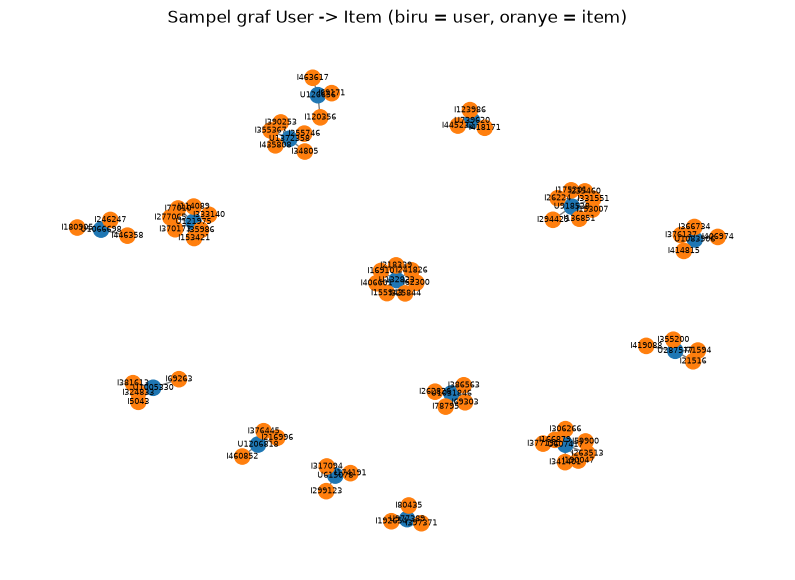

In [11]:
def plot_bipartite(M, row_names, col_names, row_tag, col_tag, n=15, seed=42, title=""):
    rng = np.random.default_rng(seed)
    deg = np.diff(M.indptr)
    cand = np.where((deg >= 3) & (deg <= 8))[0]
    pick = rng.choice(cand, size=min(n, len(cand)), replace=False)

    G = nx.Graph()
    row_nodes = set()
    for r in pick:
        rn = f"{row_tag}{row_names[r]}"
        row_nodes.add(rn)
        for c in M.indices[M.indptr[r]:M.indptr[r + 1]]:
            G.add_edge(rn, f"{col_tag}{col_names[c]}")

    colors = ["tab:blue" if x in row_nodes else "tab:orange" for x in G.nodes]
    plt.figure(figsize=(10, 7))
    nx.draw_networkx(G, pos=nx.spring_layout(G, seed=seed),
                     node_color=colors, node_size=120, font_size=6, edge_color="gray")
    plt.title(title)
    plt.axis("off")
    plt.show()

plot_bipartite(U, users, items, "U", "I",
               title="Sampel graf User -> Item (biru = user, oranye = item)")

Plot diatas adalah **sampel kecil** (15 user, seed 42), bukan seluruh graf. Setiap user
(biru) terhubung ke item yang diaksesnya (oranye). Sampel dibatasi pada user dengan
3 sampai 8 item agar plot terbaca.

## 5 VSM Item

In [ ]:
Ui = U.T.tocsr()                   
deg_i = np.diff(Ui.indptr)          

print("Shape Ui (item x user):", Ui.shape)
print("Dimensi vektor item   :", Ui.shape[1])
print("Jumlah vektor (item)  :", Ui.shape[0])
print("Nilai non-nol         :", Ui.nnz)
print("Density               :", Ui.nnz / (Ui.shape[0] * Ui.shape[1]))
print("Sparsity              :", 1 - Ui.nnz / (Ui.shape[0] * Ui.shape[1]))
print("Memori jika dense     : %.1f GB" % (Ui.shape[0] * Ui.shape[1] * 8 / 1e9))
print(pd.Series(deg_i).describe())

Shape Ui (item x user): (170615, 681413)
Dimensi vektor item   : 681413
Jumlah vektor (item)  : 170615
Nilai non-nol         : 1025824
Density               : 8.823588180381868e-06
Sparsity              : 0.9999911764118197
Memori jika dense     : 930.1 GB
count    170615.000000
mean          6.012508
std          15.483407
min           1.000000
25%           1.000000
50%           2.000000
75%           5.000000
max        1615.000000
dtype: float64


- Nilai non-nol, density, dan sparsity **identik** dengan VSM User, karena hanya transpose.
  Yang berbeda adalah dimensi dan distribusi derajat.
- Vektor item jauh lebih panjang (681.413 dimensi) tetapi **lebih padat isinya**:
  median 2 user per item dan rata-rata 6, dibanding median 1 item per user.
  Rasio rata-rata 6,01 : 1,51 ≈ 4 sama dengan rasio jumlah user terhadap item.
- Ada item yang dilihat 1.615 user, sedangkan sebagian besar item hanya dilihat sedikit user.

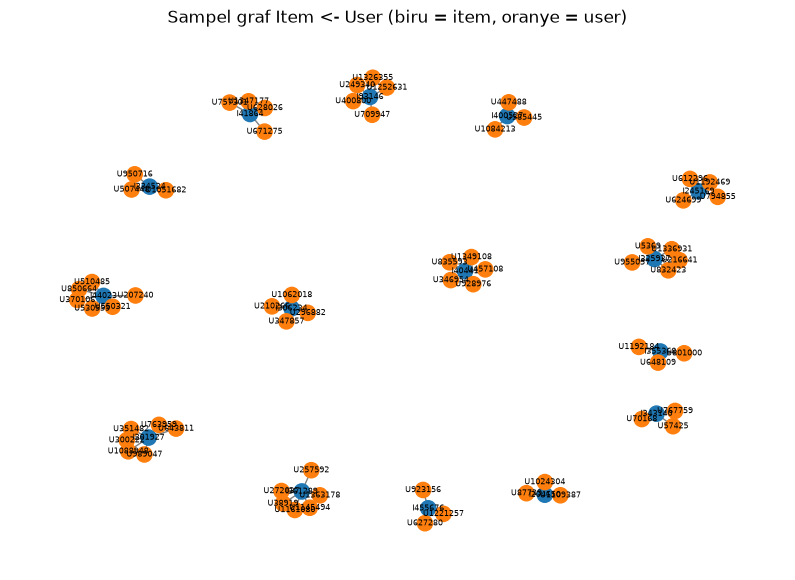

In [13]:
plot_bipartite(Ui, items, users, "I", "U",
               title="Sampel graf Item <- User (biru = item, oranye = user)")

- Plot networkx (sampel 15 item, seed 42): tiap item (biru) terhubung ke user yang
  berinteraksi dengannya (oranye)

Top item keseluruhan

In [14]:
top_items = pd.DataFrame({"itemId": items, "jumlah_user": deg_i}) \
              .sort_values("jumlah_user", ascending=False).head(10)
top_items

,itemId,jumlah_user
1968,5411,1615
113277,309778,742
135527,370653,658
122864,335975,631
108994,298009,610
94051,257040,576
140584,384302,566
129579,354233,564
80301,219512,562
168744,461686,549


## 6 Proyeksi terbaik

In [15]:
cost_user_proj = float((deg_i.astype("float64") ** 2).sum())   # U @ U.T
cost_item_proj = float((deg_u.astype("float64") ** 2).sum())   # U.T @ U

tabel = pd.DataFrame({
    "Proyeksi": ["User-User", "Item-Item"],
    "Ukuran matriks": [f"{n_u} x {n_u}", f"{n_i} x {n_i}"],
    "Memori dense (GB)": [n_u**2 * 8 / 1e9, n_i**2 * 8 / 1e9],
    "Perkiraan operasi": [cost_user_proj, cost_item_proj],
})
tabel

,Proyeksi,Ukuran matriks,Memori dense (GB),Perkiraan operasi
0,User-User,681413 x 681413,3714.589413,47070074.0
1,Item-Item,170615 x 170615,232.875826,28889190.0


Dua proyeksi yang dibandingkan:
- **User-User** = U · Uᵀ, ukuran n_user × n_user
- **Item-Item** = Uᵀ · U, ukuran n_item × n_item

Kesimpulan: proyeksi Item-Item dipilih. Lebih efisien (matriks 16× lebih kecil, operasi ≈39% lebih sedikit) dan lebih efektif (vektor item lebih padat daripada vektor user yang median-nya hanya 1 interaksi).

## 7 Similarity (Item-Item)

In [ ]:
Un = normalize(Ui)   

def topk_similar(Mn, idx, k=5):
    s = (Mn @ Mn[idx].T).toarray().ravel()
    s[idx] = -1                                  
    top = np.argpartition(-s, k)[:k]
    top = top[np.argsort(-s[top])]
    return top, s[top]

In [17]:
rng = random.Random(42)
cand = np.where((deg_i >= 20) & (deg_i <= 100))[0]
ref_idx = int(rng.choice(list(cand)))
ref_id = int(items[ref_idx])
print("Item acuan itemId:", ref_id, "| dilihat oleh", deg_i[ref_idx], "user")

top_idx, top_sim = topk_similar(Un, ref_idx, k=5)
hasil = pd.DataFrame({"itemId": items[top_idx], "similarity": top_sim})
hasil

Item acuan itemId: 89379 | dilihat oleh 43 user


,itemId,similarity
0,37972,0.285714
1,169924,0.285714
2,110489,0.285714
3,110653,0.285714
4,275217,0.285714


In [18]:
sebelum = run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah")
sebelum

,relasi,jumlah
0,VIEWED,1272750
1,ADDED_TO_CART,32681
2,BOUGHT,10829


## 7b

In [19]:
rows = [{"b": int(i), "score": float(s)} for i, s in zip(items[top_idx], top_sim)]
q_write = """
UNWIND $rows AS row
MATCH (a:Item {itemId: $a}), (b:Item {itemId: row.b})
MERGE (a)-[s:SIMILAR_TO]->(b)
SET s.score = row.score, s.metric = 'cosine'
"""
driver.execute_query(q_write, rows=rows, a=ref_id, database_=DB)
print("Relasi SIMILAR_TO ditulis")

Relasi SIMILAR_TO ditulis


### 7a 5 records with similiarity tinggi

In [20]:
q_top5 = """
MATCH (a:Item {itemId: $id})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS item, s.score AS similarity
ORDER BY similarity DESC
LIMIT 5
"""
print(q_top5)
run(q_top5, id=ref_id)


MATCH (a:Item {itemId: $id})-[s:SIMILAR_TO]->(b:Item)
RETURN b.itemId AS item, s.score AS similarity
ORDER BY similarity DESC
LIMIT 5



,item,similarity
0,110653,0.285714
1,169924,0.285714
2,110489,0.285714
3,275217,0.285714
4,37972,0.285714


# 8

In [21]:
sesudah = run("MATCH ()-[r]->() RETURN type(r) AS relasi, count(*) AS jumlah")
pd.concat([sebelum.set_index("relasi"), sesudah.set_index("relasi")],
          axis=1, keys=["sebelum", "sesudah"])

,sebelum,sesudah
,jumlah,jumlah
relasi,,
VIEWED,1272750.0,1272750
ADDED_TO_CART,32681.0,32681
BOUGHT,10829.0,10829
SIMILAR_TO,NaN,5


sebelum
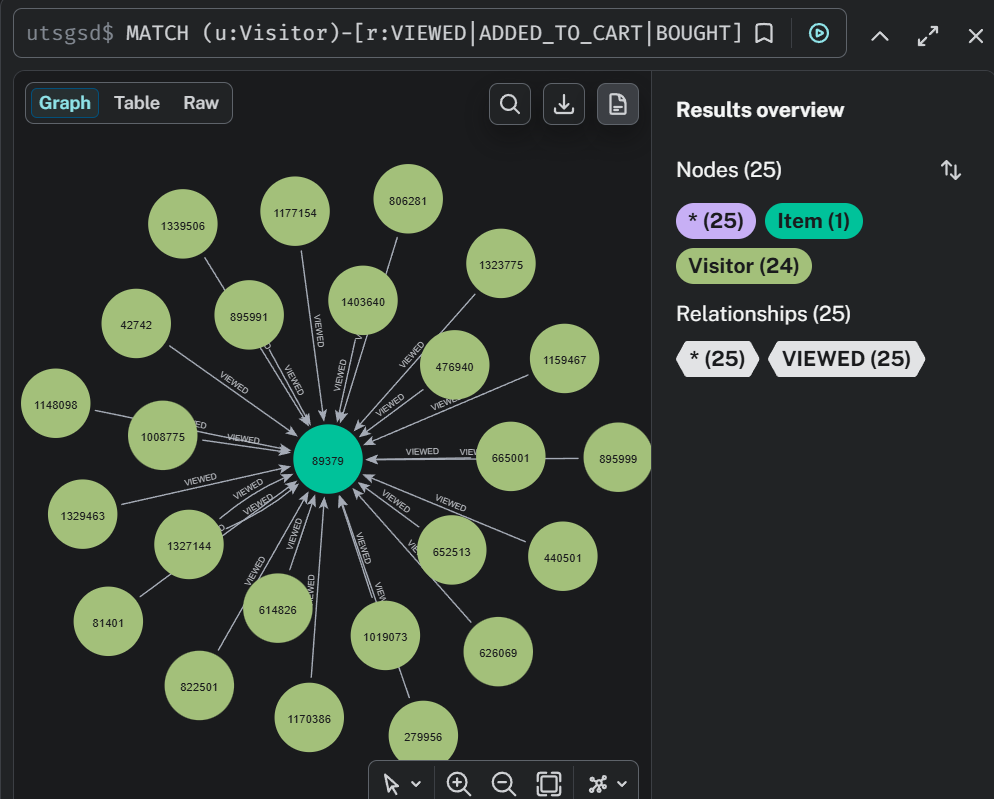

sesudah
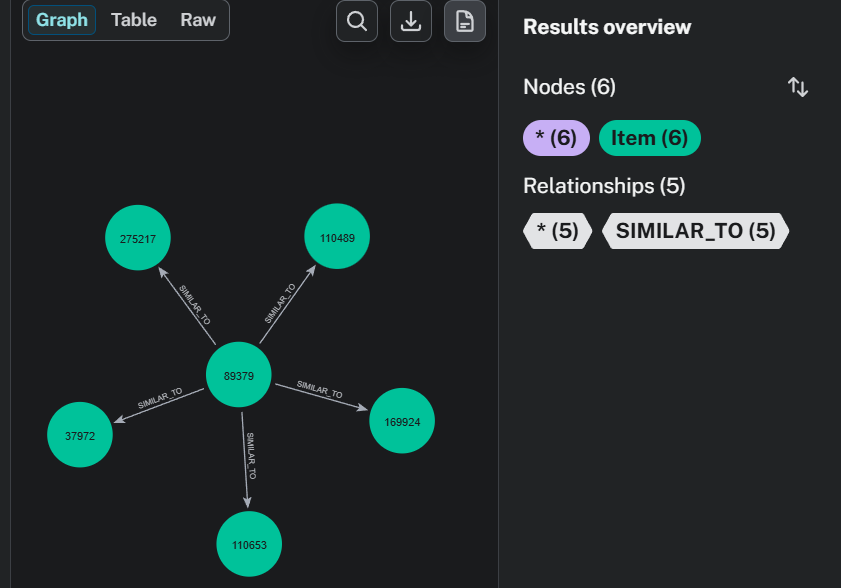

# 2.2 Analytics

In [38]:
P2 = pd.read_csv("data/events_p2.csv")
p2_items = P2.groupby("visitorid")["itemid"].apply(set)

user_pos = {int(u): i for i, u in enumerate(users)}
item_pos = {int(i): j for j, i in enumerate(items)}

def history(u):
    """Indeks item yang diakses user di P1."""
    p = user_pos[u]
    return U.indices[U.indptr[p]:U.indptr[p + 1]]

def ground_truth(u):
    """Item di P2 yang ada di katalog P1 dan belum pernah diakses user di P1."""
    seen = {int(items[j]) for j in history(u)}
    return {int(i) for i in p2_items[u] if int(i) in item_pos and int(i) not in seen}

def eligible(u):
    if u not in user_pos:
        return False
    if not (3 <= deg_u[user_pos[u]] <= 50):
        return False
    return len(ground_truth(u)) > 0

cand = sorted(int(u) for u in p2_items.index if eligible(int(u)))
print("Jumlah kandidat user:", len(cand))

Jumlah kandidat user: 2044


## 1a
### Fungsi KNN item-based
Untuk tiap item riwayat user, dicari 5 item tetangga terdekat (k = 5) dengan cosine similarity. Skor kandidat = Σ (bobot interaksi × similarity). Item yang sudah diakses dikeluarkan, lalu top-5 skor tertinggi menjadi rekomendasi. Item berbasis dipilih karena proyeksi saya menggunakan item-item

In [ ]:
def knn_recommend(u, K=5, topn=5):
    p = user_pos[u]
    hist_idx = U.indices[U.indptr[p]:U.indptr[p + 1]]
    hist_w = U.data[U.indptr[p]:U.indptr[p + 1]]

    S = (Un @ Un[hist_idx].T).toarray()
    S[hist_idx, np.arange(len(hist_idx))] = -1         

    score = np.zeros(len(items))
    tabel_knn = []
    for c, (h, w) in enumerate(zip(hist_idx, hist_w)):
        col = S[:, c]
        nb = np.lexsort((items, -col))[:K]             
        for j in nb:
            if col[j] > 0:
                score[j] += w * col[j]
        tabel_knn.append((int(items[h]),
                          [int(x) for x in items[nb]],
                          [round(float(v), 3) for v in col[nb]]))

    score[hist_idx] = -1                               
    order = np.lexsort((items, -score))[:topn]
    order = order[score[order] > 0]
    return order, score[order], tabel_knn

In [40]:
urutan = cand.copy()
random.Random(42).shuffle(urutan)           

target = None
dicoba = 0
for u in urutan:
    dicoba += 1
    top, sc, _ = knn_recommend(u, K=5, topn=5)
    if len(top) >= 3:                      
        target = u
        break

print("User dicoba sebelum ketemu:", dicoba)
print("User terpilih (visitorId):", target)
print("Item di P1:", [int(items[j]) for j in history(target)])
print("Ground truth P2:", sorted(ground_truth(target)))

User dicoba sebelum ketemu: 1
User terpilih (visitorId): 976025
Item di P1: [37471, 118720, 131201, 139638, 178554, 257040, 292400, 301656, 309778, 374130, 387747]
Ground truth P2: [192414, 223683, 282378, 350580, 437789]


In [41]:
K = 5
top_idx, top_score, tabel_knn = knn_recommend(target, K=K, topn=5)
rec = [int(items[j]) for j in top_idx]

print(f"Tetangga terdekat (k={K}) untuk tiap item riwayat user:")
for h, nbs, sims in tabel_knn:
    print(f"  item {h} -> {nbs} | sim {sims}")

Tetangga terdekat (k=5) untuk tiap item riwayat user:
  item 37471 -> [188733, 422022, 199279, 1510, 111436] | sim [0.3, 0.3, 0.3, 0.3, 0.3]
  item 118720 -> [10484, 164622, 212052, 320786, 81076] | sim [0.196, 0.196, 0.164, 0.163, 0.154]
  item 131201 -> [243697, 300165, 5470, 283163, 118720] | sim [0.124, 0.118, 0.108, 0.102, 0.08]
  item 139638 -> [385878, 22558, 151848, 188600, 256193] | sim [0.188, 0.15, 0.15, 0.15, 0.15]
  item 178554 -> [429769, 459583, 138196, 16115, 62275] | sim [0.984, 0.849, 0.838, 0.821, 0.808]
  item 257040 -> [272490, 88606, 280247, 383943, 233] | sim [0.185, 0.181, 0.177, 0.177, 0.176]
  item 292400 -> [244817, 210516, 36412, 293465, 242008] | sim [0.185, 0.167, 0.111, 0.111, 0.109]
  item 301656 -> [368221, 350525, 306448, 166179, 71336] | sim [0.603, 0.402, 0.366, 0.306, 0.193]
  item 309778 -> [315322, 445916, 428446, 220749, 342288] | sim [0.217, 0.217, 0.216, 0.212, 0.211]
  item 374130 -> [408448, 452802, 214495, 408384, 115805] | sim [0.109, 0.108

## 1b
Item yang diiklankan (k = 5)

In [42]:
hasil_rek = pd.DataFrame({"peringkat": range(1, len(rec) + 1),
                          "itemId": rec,
                          "skor": top_score.round(4)})
display(hasil_rek)
print("Top-5 rekomendasi      :", rec)
print("3 item yang diiklankan :", rec[:3])

,peringkat,itemId,skor
0,1,429769,0.9845
1,2,459583,0.8487
2,3,138196,0.8381
3,4,16115,0.8211
4,5,62275,0.8081


Top-5 rekomendasi      : [429769, 459583, 138196, 16115, 62275]
3 item yang diiklankan : [429769, 459583, 138196]


## 2a & 2b
Hit@5 dan NDCG@5

In [43]:
def hit_ndcg(rec_list, truth, n=5):
    rel = [1 if i in truth else 0 for i in rec_list[:n]]
    rel = rel + [0] * (n - len(rel))
    dcg = sum(r / np.log2(pos + 2) for pos, r in enumerate(rel))
    idcg = sum(1 / np.log2(pos + 2) for pos in range(min(len(truth), n)))
    return rel, int(any(rel)), dcg, idcg, (dcg / idcg if idcg > 0 else 0.0)

truth = ground_truth(target)
rel, hit5, dcg, idcg, ndcg5 = hit_ndcg(rec, truth)

print("Ground truth (P2)   :", sorted(truth))
print("Rekomendasi top-5   :", rec)
print("Relevansi per posisi:", rel)
print("DCG@5 =", round(dcg, 4), "| IDCG@5 =", round(idcg, 4))
print("Hit@5  =", hit5)
print("NDCG@5 =", round(ndcg5, 4))

Ground truth (P2)   : [192414, 223683, 282378, 350580, 437789]
Rekomendasi top-5   : [429769, 459583, 138196, 16115, 62275]
Relevansi per posisi: [0, 0, 0, 0, 0]
DCG@5 = 0.0 | IDCG@5 = 2.9485
Hit@5  = 0
NDCG@5 = 0.0


- **Hit@5** = 1 jika ada item top-5 yang ada di ground truth, selain itu 0.
- **NDCG@5** = DCG@5 / IDCG@5, dengan DCG = Σ rel_i / log₂(i + 1) dan relevansi biner.

Hasil: tidak ada rekomendasi yang cocok dengan ground truth (192414, 223683, 282378, 350580, 437789), sehingga **Hit@5 = 0** dan **NDCG@5 = 0** (IDCG@5 = 2,9485).
Penyebabnya: data sangat sparse, rekomendasi didominasi satu item riwayat, dan ada jeda waktu antara P1 dan P2 sehingga minat user bisa berubah.